# Example: Linearizing a Gene Circuit
Cells switch genes on and off in response to chemicals in their surroundings. Small groups of genes that regulate each other form circuits, and each circuit responds to a chemical in its own way.

In this example, we build the model of one gene circuit from its config file. We solve its ordinary differential equations (ODEs) with an ODE solver. Then we find its steady state, linearize the model there, and compare the linear and nonlinear responses to a pulse of an added chemical.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Set up a gene circuit model for an ODE solver:__ A config file lists the genes of a circuit, their rate constants, and how each gene is regulated. We'll build the model from the file and solve its balances with an ODE solver.
> * __Find a steady state and read its eigenvalues:__ A stable steady state is the state in which the circuit settles. We'll find it by running the model until it stops changing, and use the eigenvalues of the Jacobian to predict how fast the circuit settles and whether it oscillates.
> * __Compare the linear and nonlinear models:__ The linear model describes small deviations from the steady state. We'll solve it step by step with the bilinear or the zero-order hold discretization for a pulse of an added chemical, and compare it with the nonlinear model as the pulse grows.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we load the local [`Include.jl`](Include.jl) setup file and its required packages.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates [`Include.jl`](Include.jl) in the notebook's global scope. The setup file activates the course project, defines local paths, and loads the course package and the packages used here.

Let's set up our code environment:

In [1]:
# Load packages and paths from this notebook's local setup file -
include(joinpath(@__DIR__, "Include.jl"));

# Choose one theme; after changing it, rerun this cell and the plotting cells -
theme(:default)   # light background
# theme(:dark)   # dark background

Next, we choose the circuit, its starting state, the pulse of the inducer, and the discretization of the linear model. The inducer is a chemical that we add to the medium around the cells. To change any of these, you change only the settings cell below.

Except during the pulse, the inducer stays at a baseline concentration, set at the top of each circuit's file in [the `config` folder](config). Let's choose the settings:

In [2]:
# the circuit: the name of its config file in the config folder, without .toml -
circuit = "positive-autoregulation"; # or "negative-autoregulation", or "negative-feedback-loop"

# the starting state of Task 1 and of the steady-state search: zero mRNA, and this protein level for every gene -
starting_protein = 20.0; # the protein level of every gene at the start (nmol/gDW)

# the inducer pulse. The inducer I starts at its baseline, the value initial under [inputs.I] in the config file.
# At pulse_start, I changes to pulse_level. After pulse_length minutes, I returns to the baseline.
# The top panel of the Task 3 figure shows the inducer -
pulse_level = 0.6; # the inducer concentration during the pulse (µM)
pulse_start = 10.0; # the time the pulse starts (min)
pulse_length = 60.0; # how long the pulse lasts (min); the pulse ends at pulse_start + pulse_length
final_time = 480.0; # the end of each simulation (min); Task 3 stops at the last whole step at or before it

# the discretization of the linear model in Task 3: :bilinear, as in the S4 sequence model, or :zoh, the zero-order hold -
discretization = :bilinear; # or :zoh

In addition to standard Julia libraries, we'll use [the `VLDataScienceMachineLearningPackage.jl` package](https://github.com/varnerlab/VLDataScienceMachineLearningPackage.jl). Check out [the documentation](https://varnerlab.github.io/VLDataScienceMachineLearningPackage.jl/dev/) for more information on the functions, types, and data used in this material.

The gene network functions are in [the `GeneNetworks.jl` file](../../../code/src/GeneNetworks.jl) of the course package. The config files of the three circuits are in [the `config` folder](config), where you can change their constants.

___

## Gene Expression and Its Model
A __gene__ is the stretch of a cell's DNA that holds the instructions for one protein. In __transcription__, the enzyme __RNA polymerase__ copies the gene into a messenger molecule, the __mRNA__. In __translation__, the cell reads the mRNA and builds the __protein__.

Transcription starts when RNA polymerase binds the __promoter__, a stretch of DNA next to the gene. A __transcription factor__ is a protein that binds the promoter and either helps RNA polymerase bind (an __activator__) or blocks it (a __repressor__). An __inducer__ is a small molecule that we add to the medium around the cells to change how well a transcription factor binds.

### Network Motifs
A __network motif__ is a small pattern of regulation that appears in gene networks far more often than in random networks ([Shoval and Alon, 2010](https://doi.org/10.1016/j.cell.2010.09.050)).

<style>
  .course-diagram { color-scheme: light dark; }
  :host-context(body[data-vscode-theme-kind="vscode-light"]) .course-diagram,
  :host-context(body[data-vscode-theme-kind="vscode-high-contrast-light"]) .course-diagram,
  body[data-vscode-theme-kind="vscode-light"] .course-diagram,
  body[data-vscode-theme-kind="vscode-high-contrast-light"] .course-diagram { color-scheme: light; }
  :host-context(body[data-vscode-theme-kind="vscode-dark"]) .course-diagram,
  :host-context(body[data-vscode-theme-kind="vscode-high-contrast"]) .course-diagram,
  body[data-vscode-theme-kind="vscode-dark"] .course-diagram,
  body[data-vscode-theme-kind="vscode-high-contrast"] .course-diagram { color-scheme: dark; }
  body[data-jp-theme-light="true"] .course-diagram { color-scheme: light; }
  body[data-jp-theme-light="false"] .course-diagram { color-scheme: dark; }
  @media print { .course-diagram { color-scheme: only light !important; } }
</style>
<p align="center">
    <img class="course-diagram" src="figs/Fig-Motifs/Fig-Motifs.svg" width="640" style="max-width:100%; height:auto;" alt="Three gene network motifs drawn as circles. Left, negative autoregulation: a circle labeled X with a red loop from X back to X that ends in a flat bar. Middle, positive autoregulation: a circle labeled X with a blue loop from X back to X that ends in an arrowhead. Right, negative feedback loop: circles X and Y, a blue arrow from X to Y, and a red line from Y back to X that ends in a flat bar."/>
</p>

__Three network motifs.__ Each circle is a gene and its protein. Blue arrows activate, and red lines with flat ends repress.

* __Negative autoregulation:__ Protein X represses its own gene, which speeds up the response of the gene.
* __Positive autoregulation:__ Protein X activates its own gene. With steep activation, the gene can be either nearly off or fully on.
* __Negative feedback loop:__ Protein X activates gene Y, and protein Y represses gene X, which can create oscillations.

### mRNA and Protein Balances
For each gene $j$, we write balances on the mRNA level $m_{j}$ and the protein level $p_{j}$ (J. D. Varner, _Comprehensive Biotechnology_, 4th edition, in preparation):

$$
\begin{aligned}
\frac{dm_{j}}{dt} &= \underbrace{r_{X,j}\,\overbrace{u_{j}}^{\in[0,1]}}_{\text{regulated transcription}}-\underbrace{(\theta_{m,j}+\mu)\,m_{j}}_{\text{degradation and dilution}}+\underbrace{\lambda_{j}}_{\text{leak}}\\[4pt]
\frac{dp_{j}}{dt} &= \underbrace{r_{L,j}\,\overbrace{w_{j}}^{=1}}_{\text{translation}}-\underbrace{(\theta_{p,j}+\mu)\,p_{j}}_{\text{degradation and dilution}}\\[10pt]
\theta &= \frac{\ln 2}{t_{1/2}},\qquad
\mu = \frac{\ln 2}{t_{d}}
\end{aligned}
$$

Here $r_{X,j}$ and $r_{L,j}$ are the __kinetic limits__ of transcription and translation, and $u_{j}$ and $w_{j}$ are the transcriptional and translational controls. The __leak__ $\lambda_{j}$ is the unregulated transcription.

Each degradation constant $\theta$ comes from a half-life $t_{1/2}$, and the growth rate $\mu$ comes from the doubling time $t_{d}$. Levels inside the cell are in `nmol/gDW`, nanomoles per gram of dry cell weight, and time is in `min`.

### Kinetic Limits
The kinetic limits treat RNA polymerase and the ribosome as enzymes. RNA polymerase binds a gene, reads it, and leaves, and a ribosome does the same on an mRNA ([Adhikari et al., 2020](https://doi.org/10.3389/fbioe.2020.539081)). For gene $j$:

$$
\begin{aligned}
r_{X,j} &= V^{\max}_{X,j}\,\frac{G_{j}}{\tau_{X,j}K_{X,j}+(1+\tau_{X,j})\,G_{j}+\mathcal{O}_{X,j}},\qquad
V^{\max}_{X,j} = R_{X,T}\,\frac{\dot{v}_{X}}{l_{G,j}},\qquad
\tau_{X,j} = \frac{\dot{v}_{X}}{l_{G,j}}\,t_{X}\\[6pt]
r_{L,j} &= V^{\max}_{L,j}\,\frac{m_{j}}{\tau_{L,j}K_{L,j}+(1+\tau_{L,j})\,m_{j}+\mathcal{O}_{L,j}},\qquad
V^{\max}_{L,j} = K_{P}\,R_{L,T}\,\frac{\dot{v}_{L}}{l_{P,j}},\qquad
\tau_{L,j} = \frac{\dot{v}_{L}}{l_{P,j}}\,t_{L}\\[6pt]
\mathcal{O}_{X,j} &= \sum_{i\neq j}\frac{K_{X,j}\,\tau_{X,j}}{K_{X,i}\,\tau_{X,i}}\,(1+\tau_{X,i})\,G_{i},\qquad
\mathcal{O}_{L,j} = \sum_{i\neq j}\frac{K_{L,j}\,\tau_{L,j}}{K_{L,i}\,\tau_{L,i}}\,(1+\tau_{L,i})\,m_{i}
\end{aligned}
$$

Here $R_{X,T}$ and $R_{L,T}$ are the levels of RNA polymerase and ribosomes, and $\dot{v}_{X}$ and $\dot{v}_{L}$ are their elongation rates. The config gives the elongation rates in `nt/s` and `aa/s`, and the builder converts them to rates per minute. The lengths of gene $j$ and its protein are $l_{G,j}$ (`nt`) and $l_{P,j}$ (`aa`).

The __polysome amplification constant__ $K_{P}$ is the average number of ribosomes that read one mRNA at the same time. The gene level $G_{j}$ comes from the copies of gene $j$ in a cell, and $K_{X,j}$ and $K_{L,j}$ are saturation constants.

The initiation time constants $t_{X}$ and $t_{L}$ are the times to start transcription and translation. The dimensionless time constant $\tau_{X,j}$ is $t_{X}$ divided by the time $l_{G,j}/\dot{v}_{X}$ that RNA polymerase takes to read the gene. In the same way, $\tau_{L,j}$ is $t_{L}$ divided by the time $l_{P,j}/\dot{v}_{L}$ that a ribosome takes to build the protein.

The terms $\mathcal{O}_{X,j}$ and $\mathcal{O}_{L,j}$ describe the competition of the other genes for RNA polymerase and of the other mRNAs for ribosomes. Every term of $r_{X,j}$ is constant, so the kinetic limit $r_{X,j}$ is constant. The regulated transcription $r_{X,j}\,u_{j}$ changes only through the control.

### Promoter States and the Control
The promoter of gene $j$ moves among states $s\in\mathcal{S}_{j}$, such as empty, with RNA polymerase bound, or with a transcription factor bound. Each state has a __Boltzmann weight__ $\omega_{s}$. Its probability is $\omega_{s}/Z_{j}$, where the __partition function__ $Z_{j}$ sums the weights of all the states.

The controls add up the probabilities of the states that transcribe, the regulated ones in $\mathcal{A}_{j}$ and the unregulated ones in $\mathcal{B}_{j}$ ([Moon et al., 2012](https://doi.org/10.1038/nature11516); [Adhikari et al., 2020](https://doi.org/10.3389/fbioe.2020.539081)):

$$
\begin{aligned}
u_{j} &= \frac{1}{Z_{j}}\sum_{s\in\mathcal{A}_{j}}\omega_{s},\qquad
u^{\dagger}_{j} = \frac{1}{Z_{j}}\sum_{s\in\mathcal{B}_{j}}\omega_{s},\qquad
\lambda_{j} = r_{X,j}\,u^{\dagger}_{j},\qquad
Z_{j} = \sum_{s\in\mathcal{S}_{j}}\omega_{s}\\[10pt]
\omega_{s} &= W_{s}\prod_{b\in s}f_{b},\qquad
W_{s} = \exp\left(-\frac{\Delta G_{s}}{RT}\right),\qquad
f_{b} = \frac{a_{b}^{n}}{K^{n}+a_{b}^{n}},\qquad
a_{b} = p_{b}\,\frac{I^{n_{I}}}{K_{I}^{n_{I}}+I^{n_{I}}}
\end{aligned}
$$

Here $\Delta G_{s}$ is the Gibbs energy of state $s$ relative to the empty promoter (`kJ/mol`), $R$ is the gas constant, and $T$ is the absolute temperature (`K`). Each transcription factor $b$ bound in state $s$ multiplies the weight by its __bound fraction__ $f_{b}$, with the half-binding level $K$ and the binding order $n$.

The inducer concentration $I$ (`µM`) in the medium changes the controls through the bound fractions. Only the fraction of factor $b$ that carries the inducer can bind, with the half-binding concentration $K_{I}$ and the binding order $n_{I}$. A factor without an inducer has $a_{b}=p_{b}$.

In an activated gene, RNA polymerase bound alone is the state in $\mathcal{B}_{j}$, and it gives the leak. In the repressed genes of our circuits, RNA polymerase bound alone is the regulated state. These genes have no leak. A state with a repressor bound blocks transcription, and it counts only in $Z_{j}$.

___

## Task 1: Set Up the Model and Solve the Balances
In this task, we build the model of the chosen circuit from its config file. Then we solve its balances with an ODE solver.

Each config file is a [TOML](https://toml.io/en/) file. Its `[parameters]` table sets the cell, RNA polymerase, and ribosome values of the kinetic limits, the half-lives, the doubling time, and the temperature. Then the file sets the baseline inducer concentration and lists each gene with its copies per cell, the lengths of the gene and its protein, and its promoter states.

Each `[[genes.promoter]]` block is one promoter state, with its Gibbs energy `dG` in kJ/mol and whether the state transcribes the gene (`active`). Each `[[genes.promoter.bound]]` block inside it is a transcription factor bound in that state, with its half-binding level `K` and its binding order `n`. When the block names an inducer, the factor must carry the inducer before it can bind.

[The `build(...)` function](../../../code/src/Factory.jl) reads the config file of the chosen circuit into a `MyGeneNetworkModel`. It turns copies per cell and concentrations in µM into levels in `nmol/gDW` with the dry mass and the volume of a cell, and it computes the kinetic limits of each gene:

In [3]:
model = let

    # initialize -
    path = joinpath(@__DIR__, "config", circuit * ".toml"); # the config file of the chosen circuit

    # build the model from the config file -
    model = build(MyGeneNetworkModel, path); # read the file, and build the model of the circuit

    model; # return
end;

The ODE solver works with one state vector $\mathbf{x}$. For a circuit with $N$ genes, $\mathbf{x}$ holds the $N$ mRNA levels and then the $N$ protein levels, in the order of the genes in the config file. [The `balances!(...)` function](../../../code/src/GeneNetworks.jl) computes the right-hand side of the balances, $\dot{\mathbf{x}}$.

> __The balance function:__ [The `balances!(...)` function](../../../code/src/GeneNetworks.jl) takes four arguments: the vector `dx` that it fills with $\dot{\mathbf{x}}$, the state `x`, the model, and the time `t`. The solver passes our model through the third argument, which the solver calls the parameters. The `!` at the end of the name is a Julia convention: the function changes its first argument instead of returning a new vector.

[An `ODEProblem`](https://docs.sciml.ai/DiffEqDocs/stable/types/ode_types/) holds the balance function, the starting state, the time span, and the model. Let's build the starting state from the settings and set up the problem:

In [4]:
(x_start, problem) = let

    # initialize -
    N = length(model.genes); # the number of genes; the state is [m₁, ..., m_N, p₁, ..., p_N]
    x_start = zeros(2 * N); # the starting state, with every level at zero (nmol/gDW)

    # every protein starts at the level from the settings -
    for j ∈ 1:N # each gene
        x_start[N + j] = starting_protein; # the protein level of gene j (nmol/gDW)
    end

    # the ODE problem: the balance function, the starting state, the time span, and the model -
    problem = ODEProblem(balances!, x_start, (0.0, final_time), model); # the solver passes model to balances! as its parameters

    (x_start, problem); # return
end;

[The `solve(...)` function of the OrdinaryDiffEq package](https://docs.sciml.ai/DiffEqDocs/stable/getting_started/) integrates the balances over the time span. We call it as [`OrdinaryDiffEq.solve(...)`](https://docs.sciml.ai/DiffEqDocs/stable/getting_started/), because the course package also has a function with that name. [The `Tsit5` method](https://docs.sciml.ai/DiffEqDocs/stable/solvers/ode_solve/) adjusts its time step to keep the error of each step below a tolerance.

Let's solve the balances:

In [5]:
settling = let

    # initialize -
    Δt_save = 1.0; # the time between saved points of the solution (min)
    relative_tolerance = 1e-8; # the error the solver allows, relative to each level
    absolute_tolerance = 1e-12; # the error the solver allows near a level of zero (nmol/gDW)

    # solve the balances with the Tsit5 method -
    settling = OrdinaryDiffEq.solve(problem, Tsit5(); saveat = Δt_save, # save the solution every Δt_save
        reltol = relative_tolerance, abstol = absolute_tolerance); # the solution from x_start to final_time

    # checks -
    @test settling.retcode == ReturnCode.Success # the solver reached the final time

    settling; # return
end;

The solution `settling` holds the state at each saved time, and `settling.u[k]` is the state at the time `settling.t[k]`. The mRNA level of gene $j$ is entry $j$ of each state, and its protein level is entry $N+j$. Let's plot the mRNA of each gene in the top panel and its protein in the bottom panel:

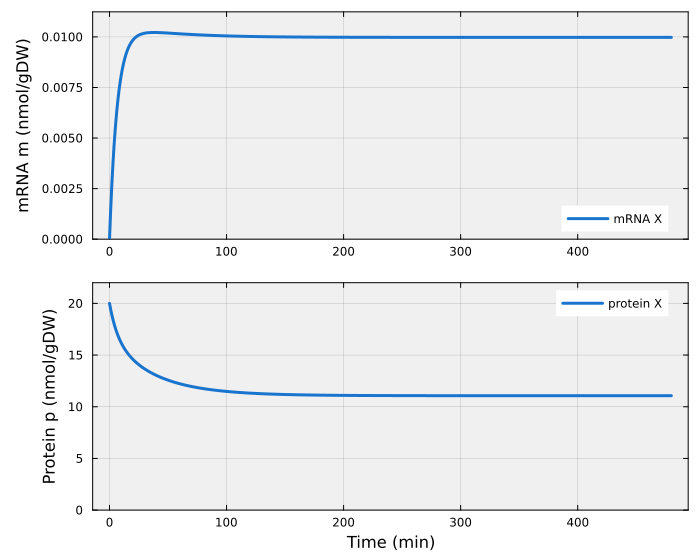

In [6]:
let

    # initialize -
    N = length(model.genes); # the number of genes
    t = settling.t; # the saved times (min)
    colors = [:dodgerblue3, :red]; # the color of gene 1 and of gene 2
    headroom = 1.1; # the top of each axis, as a multiple of the largest level in its panel
    largest_m = 0.0; # the largest mRNA level of any gene (nmol/gDW)
    largest_p = 0.0; # the largest protein level of any gene (nmol/gDW)

    # the mRNA level (top panel) and the protein level (bottom panel) of each gene against time -
    top = plot(); # an empty panel for the mRNA
    bottom = plot(); # an empty panel for the proteins
    for j ∈ 1:N # each gene
        m = zeros(length(t)); # the mRNA level of gene j at each saved time (nmol/gDW)
        p = zeros(length(t)); # the protein level of gene j at each saved time (nmol/gDW)
        for k ∈ 1:length(t) # each saved time
            m[k] = settling.u[k][j]; # the N mRNA entries come first
            p[k] = settling.u[k][N + j]; # the protein entries follow the N mRNA entries
        end
        largest_m = max(largest_m, maximum(m)); # the largest mRNA level so far
        largest_p = max(largest_p, maximum(p)); # the largest protein level so far
        color = :gray; # the color of a third or later gene
        if j <= length(colors) # gene 1 or gene 2
            color = colors[j]; # its own color
        end
        plot!(top, t, m, lw = 3, c = color, label = "mRNA " * model.genes[j].name); # the mRNA of gene j
        plot!(bottom, t, p, lw = 3, c = color, label = "protein " * model.genes[j].name); # the protein of gene j
    end

    # labels: both axes start at zero, so each curve shows its real level -
    ylabel!(top, "mRNA m (nmol/gDW)"); # the mRNA axis
    ylims!(top, (0.0, headroom * largest_m)); # the mRNA axis, from zero to just above the highest curve
    xlabel!(bottom, "Time (min)"); # the time axis
    ylabel!(bottom, "Protein p (nmol/gDW)"); # the protein axis
    ylims!(bottom, (0.0, headroom * largest_p)); # the protein axis, from zero to just above the highest curve

    # both panels: the gray panel is see-through, so the figure works in both themes -
    plot(top, bottom, layout = @layout([a; b]), link = :x, size = (700, 560), # the mRNA panel on top, and a shared time axis
        background_color_inside = RGBA(0.5, 0.5, 0.5, 0.12), framestyle = :box, fg_legend = :transparent, # a see-through gray panel in a box, and no legend border
        legend = :best, left_margin = 4Plots.mm) # the legend where it covers the least, and room for the axis labels
end

Each mRNA starts at zero, each protein starts at `starting_protein`, and both move toward a steady state, where every balance is zero. Task 2 finds that steady state by running the balances until they stop changing.

___

## Task 2: The Steady State and Its Eigenvalues
In this task, we find the steady state in which the circuit settles. Then we compute the eigenvalues of the Jacobian there, the matrix of the derivatives of each balance with respect to each level. [A `SteadyStateProblem`](https://docs.sciml.ai/DiffEqDocs/stable/types/steady_state_types/) holds the same balance function, starting state, and model as the ODE problem, with no time span.

[The `DynamicSS` method](https://docs.sciml.ai/DiffEqDocs/stable/solvers/steady_state_solve/) runs the balances from the starting state until they stop changing. Because [the `DynamicSS` method](https://docs.sciml.ai/DiffEqDocs/stable/solvers/steady_state_solve/) follows the model in time, it ends in a stable steady state, where the cells settle. For the self-activating gene, the starting protein level decides which of its two stable steady states the gene reaches.

We call the solver as [`SteadyStateDiffEq.solve(...)`](https://docs.sciml.ai/DiffEqDocs/stable/solvers/steady_state_solve/), because the course package also has a function with that name. If the circuit does not settle in a stable steady state, the cell stops with a message. Let's find the steady state:

In [7]:
x_steady = let

    # initialize -
    problem = SteadyStateProblem(balances!, x_start, model); # the balance function, the starting state, and the model
    relative_tolerance = 1e-8; # the error the solver allows, relative to each level
    absolute_tolerance = 1e-10; # the error the solver allows near a level of zero (nmol/gDW)
    tolerance = 1e-6; # the largest norm of the balances at a steady state (nmol/gDW/min)
    t_start = 0.0; # the time (min); the model has no pulse, so the inducer stays at its baseline
    N = length(model.genes); # the number of genes

    # run the balances with the Tsit5 method until they stop changing -
    solution = SteadyStateDiffEq.solve(problem, DynamicSS(Tsit5()); # DynamicSS integrates with Tsit5
        reltol = relative_tolerance, abstol = absolute_tolerance); # the steady state, when the circuit settles

    # stop with a message when the circuit does not settle -
    if solution.retcode != ReturnCode.Success # the levels never stopped changing
        error("No stable steady state was found: the circuit may oscillate without settling. Undo the last change to the config file, and rerun the notebook."); # stop here
    end
    x_steady = Vector(solution.u); # the steady state (nmol/gDW)

    # stop with the same message when the state found is not stable -
    λ = eigvals(jacobian(model, x_steady, t_start)); # the eigenvalues of the Jacobian at the state found (1/min)
    if maximum(real.(λ)) >= 0.0 # a mode that does not decay: the state is not a stable steady state
        error("No stable steady state was found: the circuit may oscillate without settling. Undo the last change to the config file, and rerun the notebook."); # stop here
    end

    # checks -
    rates = zeros(2 * N); # the rates of change at the steady state (nmol/gDW/min)
    balances!(rates, x_steady, model, t_start); # evaluate the balances there
    @test norm(rates) < tolerance # the balances are zero, to within the tolerance

    x_steady; # return
end;

Near the steady state, the response to a small push is a sum of modes, one for each eigenvalue $\lambda$ of the Jacobian. A mode changes as $e^{\lambda t}$, and it decays when the real part of $\lambda$ is negative. Its __time constant__ $1/|\mathrm{Re}\,\lambda|$ is the time in which the mode decays by a factor of $e$.

A complex pair of eigenvalues, $a\pm bi$, makes its modes oscillate with the __period__ $2\pi/|b|$. [The `jacobian(...)` function](../../../code/src/GeneNetworks.jl) computes the Jacobian by central differences. Let's compute the eigenvalues at the steady state, with one row for each real eigenvalue or complex pair:

In [8]:
let

    # initialize -
    t_start = 0.0; # the time at which the Jacobian is evaluated (min)
    λ = eigvals(jacobian(model, x_steady, t_start)); # the eigenvalues of the Jacobian at the steady state (1/min)
    column_labels = ["eigenvalue (1/min)", "mode", "time constant (min)", "period (min)"]; # the headers of the table columns
    values = String[]; # column 1: each real eigenvalue, or each complex pair a ± bi
    modes = String[]; # column 2: whether the mode of each eigenvalue decays, grows, or oscillates
    time_constants = String[]; # column 3: the time constant 1/|Re λ| of each mode
    periods = String[]; # column 4: the period 2π/|Im λ| of an oscillating mode

    # one row for each real eigenvalue, and one row for each complex pair -
    for k ∈ 1:length(λ) # each eigenvalue
        if imag(λ[k]) < 0.0 # one half of a complex pair; the pair gets one row, from its other half
            continue; # skip this half
        end
        a = round(real(λ[k]); sigdigits = 3); # the real part (1/min)
        b = round(imag(λ[k]); sigdigits = 3); # the imaginary part (1/min)
        push!(time_constants, string(round(1.0 / abs(real(λ[k])); sigdigits = 3))); # the time constant (min)
        mode = "neither decays nor grows"; # a real part of zero
        if real(λ[k]) < 0.0 # a negative real part: the mode decays
            mode = "decays"; # the mode shrinks over time
        elseif real(λ[k]) > 0.0 # a positive real part: the mode grows
            mode = "grows"; # the mode grows over time
        end
        if imag(λ[k]) > 0.0 # a complex pair, a ± bi: the mode also oscillates
            push!(values, string(a) * " ± " * string(b) * "i"); # the pair (1/min)
            push!(periods, string(round(2π / imag(λ[k]); sigdigits = 3))); # the period (min)
            mode = mode * " and oscillates"; # add the oscillation to the mode
        else # a real eigenvalue
            push!(values, string(a)); # the eigenvalue (1/min)
            push!(periods, "none"); # no oscillation
        end
        push!(modes, mode); # store the mode
    end
    table = hcat(values, modes, time_constants, periods); # one row for each real eigenvalue or complex pair

    # show the table -
    pretty_table(table; # the table
        backend = :text, # draw the table with text characters
        column_labels = column_labels, # the header of each column
        fit_table_in_display_horizontally = false, # show every column, even when the table is wider than the display
        alignment = :l); # left-align every column (the default is right)
end

┌────────────────────┬────────┬─────────────────────┬──────────────┐
│ eigenvalue (1/min) │ mode   │ time constant (min) │ period (min) │
├────────────────────┼────────┼─────────────────────┼──────────────┤
│ -0.157             │ decays │ 6.38                │ none         │
│ -0.0248            │ decays │ 40.4                │ none         │
└────────────────────┴────────┴─────────────────────┴──────────────┘


Every eigenvalue in the table has a negative real part, because Task 2 accepts only a stable steady state. The mode with the largest time constant decays the slowest, and it sets how long the circuit takes to settle in the Task 1 plot. A complex pair gives modes that oscillate as they decay, with the period in the table.

___

## Task 3: Linearize the Model and Compare the Responses
In this task, we linearize the circuit about its steady state, with the transcriptional controls as the input. Then we run the pulse from the settings cell through the linear and the nonlinear model, and compare the two responses.

### Linearization about the Steady State
The inducer reaches the balances only through the probabilities of the promoter states, which set both the control $u_{j}$ and the leak $\lambda_{j}=r_{X,j}\,u^{\dagger}_{j}$. The input of the linear model is the total control $\bar{u}_{j}=u_{j}+u^{\dagger}_{j}$. The deviations from the steady state $\mathbf{x}^{\star}$ of Task 2 are $\Delta\mathbf{x}=\mathbf{x}-\mathbf{x}^{\star}$ and $\Delta\bar{u}_{j}$, the change in $\bar{u}_{j}$ that the inducer causes with every level held at $\mathbf{x}^{\star}$.

The input matrix $\mathbf{B}$ holds $r_{X,j}$ in the row of $m_{j}$ and the column of gene $j$, and zeros elsewhere, because $\dot{m}_{j}=r_{X,j}\,\bar{u}_{j}-(\theta_{m,j}+\mu)\,m_{j}$. The state matrix $\mathbf{A}$ is the Jacobian from Task 2, which holds the feedback of the proteins on the controls. Let's linearize the circuit, and compute $\bar{\mathbf{A}}$ and $\bar{\mathbf{B}}$ with [the `discretize(...)` function](../../../code/src/GeneNetworks.jl) for the step $\Delta t$ and the setting `discretization`:

In [9]:
(A, B, Ā, B̄, Δt) = let

    # initialize -
    t_start = 0.0; # the time (min); the model has no pulse, so the inducer stays at its baseline
    Δt = 1.0; # the time step of the recursion (min)
    N = length(model.genes); # the number of genes

    # the state matrix: the Jacobian at the steady state, which includes how the proteins change the controls -
    A = jacobian(model, x_steady, t_start); # the state matrix (1/min)

    # the input matrix: the mRNA balance of gene j changes by r_X,j for each unit of its control ū_j -
    B = zeros(2 * N, N); # one row for each balance, and one column for the control of each gene
    for j ∈ 1:N # each gene
        B[j, j] = transcription_rate(model, j); # r_X,j, the transcription kinetic limit, in the row of m_j (nmol/gDW/min)
    end

    # the discretization that the settings cell chooses -
    (Ā, B̄) = discretize(A, B; Δt = Δt, method = discretization); # the matrices of the recursion for this time step

    (A, B, Ā, B̄, Δt); # return
end;

### Pulse Responses
The settings cell sets the pulse with three values. The inducer changes to `pulse_level` at the time `pulse_start`, and returns to its baseline after `pulse_length` minutes. The baseline is the value `initial` under `[inputs.I]` in the config file of the circuit.

Both models use the pulse edges rounded to whole steps of $\Delta t$. Let's set the schedule on a copy of the model with [the `set_input!(...)` function](../../../code/src/GeneNetworks.jl):

In [10]:
trial = let # a copy of the model, with the inducer schedule of the pulse

    # initialize -
    baseline = model.inputs["I"].initial; # the baseline inducer concentration from the config file (µM)
    pulse_on = round(pulse_start / Δt) * Δt; # the time the pulse starts, rounded to a whole step (min)
    pulse_end = round((pulse_start + pulse_length) / Δt) * Δt; # the time the pulse ends, rounded to a whole step (min)

    # a copy of the model with the pulse: I is pulse_level from pulse_on, and the baseline again from pulse_end -
    trial = deepcopy(model); # a copy, so that the pulse does not change the model of Tasks 1 and 2
    set_input!(trial, "I", [pulse_on, pulse_end], [pulse_level, baseline]); # the two times at which I changes, and its value after each

    trial; # return
end;

For the linear model, [the `transcription_control(...)` function](../../../code/src/GeneNetworks.jl) computes $\bar{u}_{j}$ from the promoter states, with every level at the steady state and the inducer of each step. We run the recursion on the deviations, $\Delta\mathbf{x}_{k}=\bar{\mathbf{A}}\,\Delta\mathbf{x}_{k-1}+\bar{\mathbf{B}}\,\Delta\bar{\mathbf{u}}_{k}$, starting from $\Delta\mathbf{x}_{0}=\mathbf{0}$. The vector $\Delta\bar{\mathbf{u}}_{k}$ holds the input deviation of each gene over step $k$.

For the nonlinear model, we call [the `solve(...)` function of the OrdinaryDiffEq package](https://docs.sciml.ai/DiffEqDocs/stable/getting_started/) as in Task 1, starting from the steady state. Both models use the schedule above. Let's run the pulse through both models:

In [11]:
pulse = let # the pulse through the linear and the nonlinear model

    # initialize -
    N = length(model.genes); # the number of genes
    t_start = 0.0; # the time (min); the model has no pulse, so the inducer stays at its baseline
    number_of_steps = floor(Int, final_time / Δt); # the number of recursion steps that fit before the final time
    relative_tolerance = 1e-8; # the error the solver allows, relative to each level
    absolute_tolerance = 1e-12; # the error the solver allows near a level of zero (nmol/gDW)

    # the total control of each gene at the steady state, with the inducer at its baseline -
    ū_steady = zeros(N); # the control ū_j of each gene at the steady state
    for j ∈ 1:N # each gene
        ū_steady[j] = transcription_control(model, j, x_steady, t_start); # the probability that the promoter of gene j transcribes
    end

    # the recursion on the deviations from the steady state -
    t = zeros(number_of_steps + 1); # the times t_k (min)
    I = zeros(number_of_steps + 1); # the inducer concentration at each time (µM)
    p_linear = zeros(number_of_steps + 1, N); # the protein level of each gene in the linear model (nmol/gDW)
    Δx = zeros(2 * N); # the deviation starts at zero
    Δū = zeros(N); # the input deviation of each gene over one step
    I[1] = input_value(trial, "I", t[1]); # the inducer concentration at t = 0 (µM)
    for j ∈ 1:N # each gene
        p_linear[1, j] = x_steady[N + j]; # the protein starts at the steady state
    end
    for k ∈ 1:number_of_steps # each step of the recursion
        t[k + 1] = k * Δt; # the time at the end of step k (min)
        for j ∈ 1:N # each gene
            Δū[j] = transcription_control(trial, j, x_steady, t[k]) - ū_steady[j]; # the change in ū_j that the inducer causes over step k, with every level at the steady state
        end
        Δx = Ā * Δx + B̄ * Δū; # one step of the recursion
        for j ∈ 1:N # each gene
            p_linear[k + 1, j] = x_steady[N + j] + Δx[N + j]; # the protein level: the steady state plus the deviation (nmol/gDW)
        end
        I[k + 1] = input_value(trial, "I", t[k + 1]); # the inducer concentration at the end of step k (µM)
    end

    # the pulse edges inside the time span, where the solver must stop -
    edges = Float64[]; # the times at which the inducer jumps
    for time ∈ trial.inputs["I"].times # each time at which the schedule changes the inducer
        if time < t[end] # the change happens inside the time span
            push!(edges, time); # the solver stops there
        end
    end

    # the nonlinear balances, from the steady state -
    problem = ODEProblem(balances!, x_steady, (0.0, t[end]), trial); # start at the steady state, and run to the last recursion time
    solution = OrdinaryDiffEq.solve(problem, Tsit5(); tstops = edges, saveat = t, # stop at the pulse edges, and save at the recursion times
        reltol = relative_tolerance, abstol = absolute_tolerance); # the nonlinear response
    p_nonlinear = zeros(length(t), N); # the protein level of each gene in the nonlinear model (nmol/gDW)
    for k ∈ 1:length(t) # each saved time
        for j ∈ 1:N # each gene
            p_nonlinear[k, j] = solution.u[k][N + j]; # the protein entries follow the N mRNA entries
        end
    end

    # checks -
    @test solution.retcode == ReturnCode.Success # the solver reached the last recursion time

    (t = t, I = I, p_linear = p_linear, p_nonlinear = p_nonlinear); # return
end;

The result `pulse` holds the times, the inducer, and the protein levels of both models, with one column for each gene. Let's plot the inducer in the top panel, and the protein level of each gene in the bottom panel, with the nonlinear model solid and the linear model dashed:

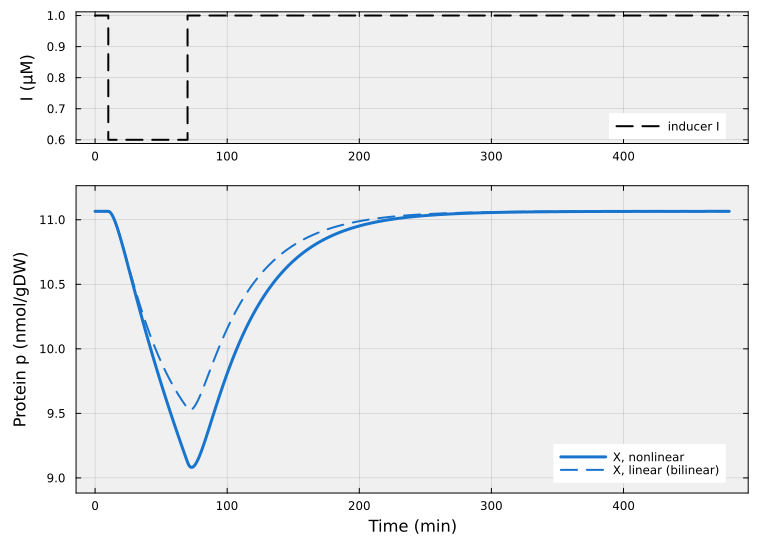

In [12]:
let

    # initialize -
    N = length(model.genes); # the number of genes
    colors = [:dodgerblue3, :red]; # the color of gene 1 and of gene 2
    margin = 0.1; # the space above and below the curves, as a fraction of their range
    smallest_range = 1e-3; # the smallest height of the protein axis, as a fraction of the largest level, so that round-off does not fill the panel
    largest = -Inf; # the largest protein level of either model (nmol/gDW)
    smallest = Inf; # the smallest protein level of either model (nmol/gDW)

    # top panel: the inducer, as a dashed step line in the color of the legend text -
    top = plot(); # an empty panel for the inducer
    inducer_color = top[1][:legend_font_color]; # black on the light theme, white on the dark theme
    plot!(top, pulse.t, pulse.I, seriestype = :steppost, lw = 2, ls = :dash, c = inducer_color, label = "inducer I"); # the inducer concentration, held constant over each step
    ylabel!(top, "I (µM)"); # the inducer axis

    # bottom panel: the protein of each gene, nonlinear solid and linear dashed -
    bottom = plot(); # an empty panel for the proteins
    for j ∈ 1:N # each gene
        color = :gray; # the color of a third or later gene
        if j <= length(colors) # gene 1 or gene 2
            color = colors[j]; # its own color
        end
        name = model.genes[j].name; # the name of gene j
        plot!(bottom, pulse.t, pulse.p_nonlinear[:, j], lw = 3, c = color, label = name * ", nonlinear"); # the nonlinear model, solid
        plot!(bottom, pulse.t, pulse.p_linear[:, j], lw = 2, ls = :dash, c = color, label = name * ", linear (" * string(discretization) * ")"); # the linear model, dashed, with its discretization
        largest = max(largest, maximum(pulse.p_nonlinear[:, j]), maximum(pulse.p_linear[:, j])); # the largest protein level so far
        smallest = min(smallest, minimum(pulse.p_nonlinear[:, j]), minimum(pulse.p_linear[:, j])); # the smallest protein level so far
    end

    # the protein axis follows the curves, with a margin above and below -
    span = largest - smallest; # the range of the protein levels (nmol/gDW)
    if span < smallest_range * largest # the curves are nearly flat
        span = smallest_range * largest; # a taller axis, so that a pulse with no effect plots as a flat line
    end
    middle = (largest + smallest) / 2; # the middle of the protein levels (nmol/gDW)
    half_height = (0.5 + margin) * span; # half the height of the protein axis (nmol/gDW)
    xlabel!(bottom, "Time (min)"); # the time axis
    ylabel!(bottom, "Protein p (nmol/gDW)"); # the protein axis
    ylims!(bottom, (middle - half_height, middle + half_height)); # the protein axis, from just below the lowest curve to just above the highest

    # both panels: the gray panel is see-through, so the figure works in both themes -
    plot(top, bottom, layout = @layout([a{0.3h}; b]), link = :x, size = (760, 540), # the inducer panel on top, 30% of the height, and a shared time axis
        background_color_inside = RGBA(0.5, 0.5, 0.5, 0.12), framestyle = :box, fg_legend = :transparent, # a see-through gray panel in a box, and no legend border
        legend = :best, left_margin = 4Plots.mm) # the legend where it covers the least, and room for the protein axis label
end

The linear model holds only near the steady state. When the pulse keeps the circuit near the steady state, the two models agree. When the pulse takes the circuit far from the steady state, the two models disagree.

A long enough pulse can switch the self-activating gene to its other stable steady state. The linear model cannot predict this switch, because it describes only the steady state it was linearized about.

### Things to Try
Make one of these changes at a time, rerun the notebook, and look at the figures:

* __A longer removal:__ For the self-activating gene, set `pulse_level` to `0.0` and `pulse_length` to `150`. The gene switches to its low steady state and stays there, while the linear model returns to the high steady state.
* __The zero-order hold:__ Set `discretization` to `:zoh`, and set a larger `Δt` in the linearize cell. The zero-order hold stays exact for the linear model at each step, while the bilinear discretization loses accuracy as the step grows.
* __Another circuit:__ Set `circuit` to `"negative-feedback-loop"` and `final_time` to `960`. The two proteins oscillate as they settle, with the period from the eigenvalue table.

___

## Summary
In this example, we built the model of a gene circuit from its config file, found its steady state with an ODE solver, and compared the linearized model with the nonlinear model for an inducer pulse.

> __Key Takeaways:__
>
> * __A config file and a balance function define the model:__ The config file lists the genes, rate constants, and promoter states of a circuit. The ODE solver needs only the balance function, the starting state, the time span, and the model.
>
> * __The eigenvalues at the steady state predict how the circuit settles:__ The time constant of the slowest mode sets how long the circuit takes to settle. A complex pair of eigenvalues makes the circuit oscillate as it settles, with a period set by the imaginary part.
>
> * __The linear model holds only near the steady state:__ For a small pulse, the linear model follows the nonlinear response. For a large pulse, the nonlinear model can move far from the steady state or switch to another steady state, which the linear model cannot predict.

___